# 07b · Estrategias, sensibilidad, local/global, semillas y actualización

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "data.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Ejecutar desde el repositorio DL-LAB09")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from src import data as D, metrics as M, backtest as B
RUN_TRAIN = False  # Cambiar a True solo para generar artefactos que falten.


Los barridos y la elección del mejor modelo usan validación. El global de 150 clientes se compara con diez modelos locales sobre los mismos diez IDs. Los experimentos de semillas y actualización congelan configuración antes de prueba.

In [2]:
if RUN_TRAIN:
    import subprocess
    subprocess.run([sys.executable,"-m","src.run_cisco","--stage","experiments"],cwd=ROOT,check=True)

In [3]:
exp=ROOT/"outputs"/"runs"/"experimentos_B"
for name in ["sensibilidad.csv","baseline_L.csv","local_global.csv"]:
    display(Markdown(f"### {name}"))
    display(pd.read_csv(exp/name))
display(json.loads((exp/"best_dl_selection.json").read_text()))

### sensibilidad.csv

,modelo,L,meses,val_MAE,val_MASE,train_s,epochs_max,max_batches_per_epoch
0,LSTM_Multi,48,30,141.523682,1.494123,3.125478,6,50
1,LSTM_Multi,168,30,142.638214,1.501184,7.826257,6,50
2,LSTM_Multi,336,30,141.516937,1.510969,18.440584,6,50
3,LSTM_Multi,168,3,188.501587,1.772411,9.406685,6,50
4,LSTM_Multi,168,12,139.256073,1.513081,9.867757,6,50


### baseline_L.csv

,modelo,L,L_efectivo,val_MASE,fuente,train_s
0,SeasonalNaive24,48,24,0.985479,A: barrido_historia.csv; invariancia exacta pa...,0.000000
1,SeasonalNaive24,168,24,0.985479,A: barrido_historia.csv; invariancia exacta pa...,0.000000
2,SeasonalNaive24,336,24,0.985479,A: barrido_historia.csv; invariancia exacta pa...,0.000000
3,LightGBM,48,24,0.951847,"B CPU: mismos parámetros de A/historia, sin re...",65.575525
4,LightGBM,168,168,0.857282,"A: barrido_historia.csv; rezagos fijos 1-24,16...",37.143831
5,LightGBM,336,168,0.857282,"A: barrido_historia.csv; rezagos fijos 1-24,16...",37.143831


### local_global.csv

,alcance,MAE,RMSE,WAPE,MAPE,MAPE_excluidas,MASE,n,train_s,params
0,global_150_evaluado_10,117.871224,354.538055,0.075541,0.276581,0,1.623391,22080,7.826257,22728
1,local_10,130.114256,373.426146,0.083388,0.219711,0,1.815385,22080,22.192907,227280


{'criterio': 'MASE validación, todas las familias A y B',
 'mejor': {'modelo': 'iTransformer',
  'hardware': 'NVIDIA GeForce RTX 5070 Laptop GPU',
  'inference_s': 16.308844091001447,
  'familia': 'Atención',
  'L': 168,
  'estrategia': 'multi-salida',
  'covariables': False,
  'config': 'iTransformer_256',
  'params_total': 1631256,
  'params_entrenables': 1631256,
  'train_s': 75.65557766099846,
  'val_MASE': 0.8079002902662759,
  'gpu_mem_pico_MB': 291.19580078125,
  'MAE': 56.58839372133602,
  'RMSE': 504.3241843692249,
  'WAPE': 0.0724066785177932,
  'MAPE': 0.11093622938074768,
  'MASE': 0.808574097497639,
  'MASE_navidad': 1.386156427894011},
 'candidatos': [{'modelo': 'DLinear', 'val_MASE': 0.8797428607940674},
  {'modelo': 'MLP', 'val_MASE': 0.8200646042823792},
  {'modelo': 'NLinear', 'val_MASE': 0.8778082728385925},
  {'modelo': 'PatchTST', 'val_MASE': 0.8568459874851447},
  {'modelo': 'iTransformer', 'val_MASE': 0.8079002902662759},
  {'modelo': 'LSTM_AR', 'val_MASE': 1.957

In [4]:
tab=pd.read_csv(ROOT/"outputs"/"tables"/"todos_resultados.csv")
display(tab.loc[tab.familia.isin(["Semillas","Reentrenamiento"])])
seeds=tab.loc[tab.familia=="Semillas"]
display(seeds[["MAE","MASE"]].agg(["mean","std"]))

,modelo,hardware,inference_s,familia,L,estrategia,covariables,train_s,model_id,load_s,...,hidden,epochs,max_batches_per_epoch,train_s_search_total,train_s_criterio,arboles,seleccion,params_referencia,nota,pasos
4,LightGBM_mensual,CPU (AMD Ryzen AI 7 350 w/ Radeon 860M),25.454578,Reentrenamiento,168,mensual expandible,True,270.994094,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,validación; configuración congelada antes de p...,"Conteo del modelo de diciembre, reconstruido c...",NaN,NaN
6,iTransformer_seed123,CPU (AMD Ryzen AI 7 350 w/ Radeon 860M),8.723035,Semillas,168,multi-salida,False,107.100026,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,200.0
7,iTransformer_seed7,CPU (AMD Ryzen AI 7 350 w/ Radeon 860M),12.907734,Semillas,168,multi-salida,False,106.113543,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,200.0
8,iTransformer_seed42,CPU (AMD Ryzen AI 7 350 w/ Radeon 860M),8.520562,Semillas,168,multi-salida,False,99.367641,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,200.0
9,iTransformer_mensual,CPU (AMD Ryzen AI 7 350 w/ Radeon 860M),8.863162,Reentrenamiento,168,mensual expandible,False,317.668434,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,200.0


,MAE,MASE
mean,62.407530,0.897694
std,1.489967,0.008323


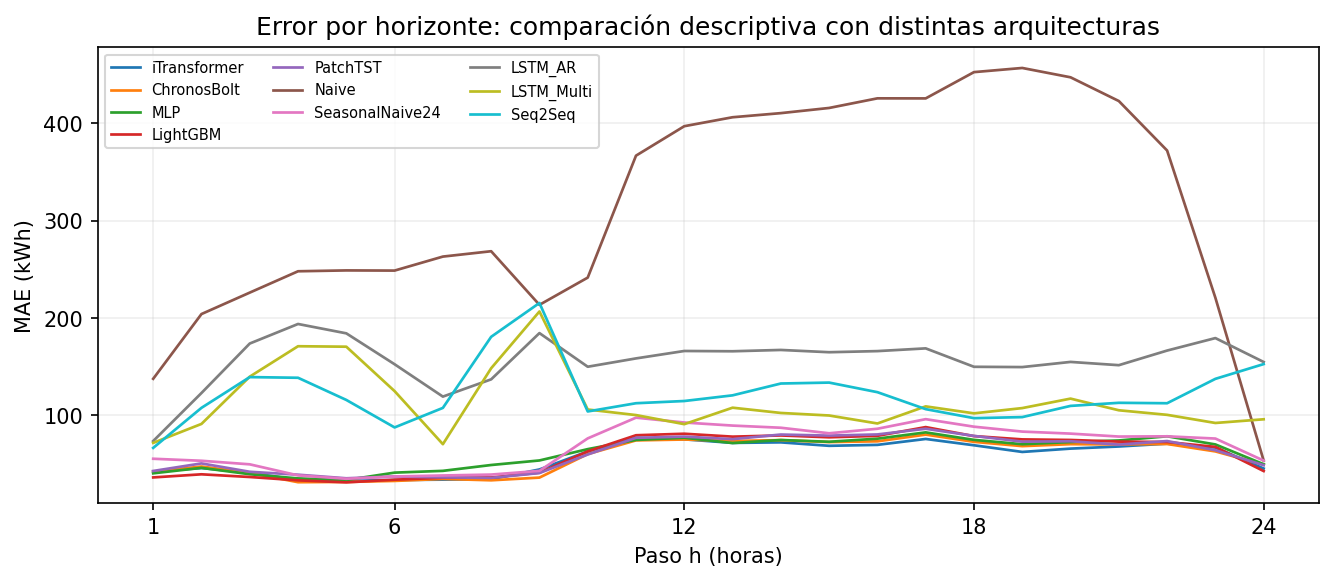

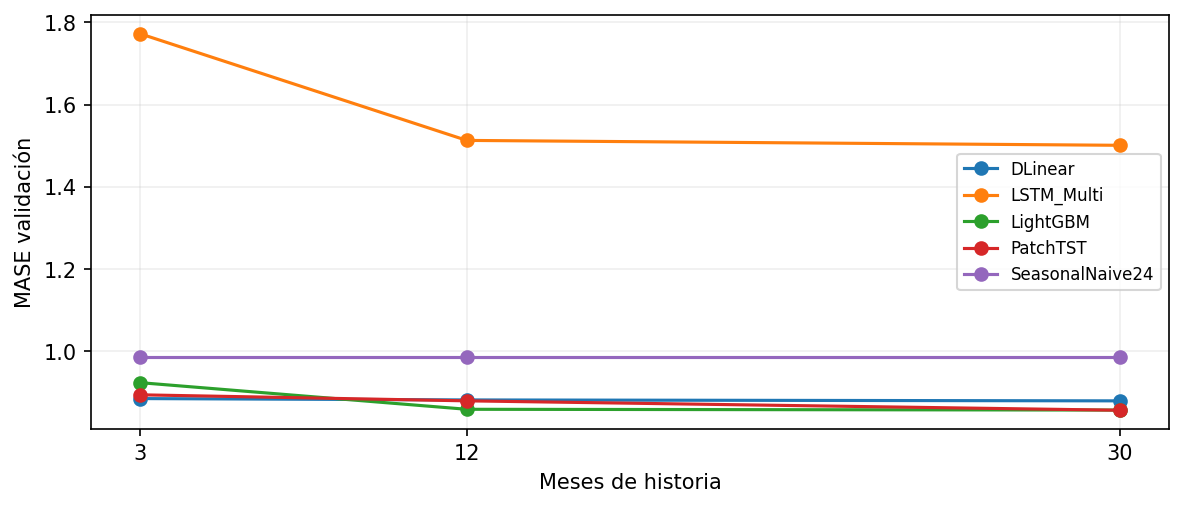

In [5]:
for name in ["mae_por_h","mase_vs_historia"]:
    display(Image(filename=str(ROOT/"outputs"/"figs"/f"{name}.png")))